# Household Expenditure Structure: Bulgaria vs the EU

Final exam project, Data Science module.

**Author:** Yana Atanasova  
**Date:** November 2026

## 1. Introduction and Problem Formulation

_Describe the problem, why it matters, the research questions, the scope and the assumptions._

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

# Project root: works from the repo root and from the notebooks/ folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"

## 2. Data Loading

**Source 1: Eurostat, Household Budget Survey (HBS).**
Table `hbs_str_t211`: structure of consumption expenditure by COICOP category (in per mille).

- URL: https://ec.europa.eu/eurostat/databrowser/view/hbs_str_t211/default/table?lang=en
- Downloaded: 15 November 2026 (SDMX-CSV 1.0, full dataset, gzip-compressed)
- File: `data/raw/hbs_str_t211.csv.gz` (never modified)
- Coverage: 7 survey waves (1988, 1994, 1999, 2005, 2010, 2015, 2020), 38 geographic entities, 218 COICOP categories

**Source 2: World Bank, World Development Indicators.**
Indicator `NY.GDP.PCAP.PP.CD`: GDP per capita, PPP (current international $).

- URL: https://data.worldbank.org/indicator/NY.GDP.PCAP.PP.CD
- Downloaded: 23 November 2026 (CSV)
- File: `data/raw/API_NY.GDP.PCAP.PP.CD_DS2_en_csv_v2_78481.csv` (never modified)
- Coverage: 266 countries and aggregates, 1960-2025 (PPP values are available from 1990)

The two sources are independent (an EU statistical office and an international development institution). They are joined by country and year in section 4.

In [2]:
# Eurostat table hbs_str_t211 (downloaded as a gzip-compressed CSV)
hbs = pd.read_csv(RAW_DIR / "hbs_str_t211.csv.gz")

print(hbs.shape)
hbs.head(10)

(29425, 10)


,DATAFLOW,LAST UPDATE,freq,coicop,unit,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG,CONF_STATUS
0,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,1994,154,NaN,NaN
1,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,1999,134,NaN,NaN
2,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,2005,130,NaN,NaN
3,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,2010,121,NaN,NaN
4,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,2015,118,NaN,NaN
5,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,2020,120,NaN,NaN
6,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Belgium,1988,161,NaN,NaN
7,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Belgium,1994,120,NaN,NaN
8,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Belgium,1999,133,NaN,NaN
9,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Belgium,2005,135,NaN,NaN


In [3]:
# World Bank: GDP per capita, PPP (current international $), indicator NY.GDP.PCAP.PP.CD.
# The file name contains a version number, so it is found with a pattern.
wb_path = next(RAW_DIR.glob("API_NY.GDP.PCAP.PP.CD_DS2_en_csv_v2_*.csv"))
print(wb_path.name)

# The first 4 lines of the World Bank CSV are metadata, not data
wb = pd.read_csv(wb_path, skiprows=4)

print(wb.shape)
wb.head()

API_NY.GDP.PCAP.PP.CD_DS2_en_csv_v2_78481.csv
(266, 71)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,...,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,31888.508736,32507.084315,35059.273098,35098.797669,35937.594656,37768.566013,38904.999247,34339.939156,33729.511909,35324.072064,34095.647171,35901.645961,35657.287197,35972.859662,36117.535262,37524.914920,39287.059713,38554.716783,28733.604511,35207.170909,41863.273996,47521.876547,51712.153136,NaN,NaN
1,Africa Eastern and Southern,AFE,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2302.708459,2357.601145,2489.965865,2653.625259,2840.188971,3028.524393,3137.661364,3100.136231,3216.301443,3319.704951,3244.317034,3373.428766,3513.894491,3539.428265,3639.496476,3843.028379,3727.710785,3804.533834,3707.033612,4022.277659,4359.591407,4496.744898,4635.125049,4840.265200,NaN
2,Afghanistan,AFG,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,926.507941,966.962032,971.633503,1076.087353,1121.834471,1286.949843,1333.747267,1570.698145,1765.538028,1744.060623,1988.429304,2133.241271,2224.490748,2284.075848,2213.181441,2335.795862,2432.276701,2583.485332,2561.981761,2144.166570,2122.659362,2203.537619,2236.199073,NaN,NaN
3,Africa Western and Central,AFW,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2811.138615,2952.023306,3188.647508,3384.832366,3574.075153,3767.066758,3968.376865,4127.756262,4351.692249,4536.837322,4666.588518,4867.130763,5121.421991,5063.905375,4972.623859,5035.762391,5188.368000,5491.687935,5423.594405,5702.134886,6232.323014,6538.812038,6840.333882,7184.664483,NaN
4,Angola,AGO,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4241.291501,4322.197732,4770.688026,5415.612120,6017.818163,6727.963288,7315.602330,7227.563642,7411.654609,7537.596564,8246.360812,8504.095321,9017.690182,8067.485847,7882.513705,8125.706394,8370.228758,8621.659308,7782.151534,8720.187687,9373.408309,9549.793139,9963.590209,10251.345706,NaN


## 3. Data Cleaning and Validation

This section selects the relevant categories, validates the data and makes the housing group comparable across countries and years.

### 3.1 Selecting countries and top-level categories

In [4]:
# How many unique values does each dimension have?
for col in ["freq", "unit", "coicop", "geo", "TIME_PERIOD"]:
    print(col, hbs[col].nunique(), "unique values")
    print(sorted(hbs[col].unique())[:15], "\n")

freq 1 unique values
['Annual'] 

unit 1 unique values
['Per mille'] 

coicop 218 unique values
['Accommodation services', 'Actual rentals for housing', 'Actual rentals paid by tenants', 'Alcoholic beverages', 'Alcoholic beverages, tobacco and narcotics', 'Animal drawn vehicles', 'Apples (fresh, chilled or frozen)', 'Audio-visual, photographic and information processing equipment', "Baker's yeast, dessert preparations, soups", 'Bananas (fresh, chilled or frozen)', 'Beef and veal', 'Beer', 'Berries (fresh, chilled or frozen)', 'Bicycles', 'Books'] 

geo 38 unique values
['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'European Union - 15 countries (1995-2004)', 'European Union - 25 countries (2004-2006)', 'European Union - 27 countries (2007-2013)', 'European Union - 27 countries (from 2020)', 'Finland', 'France', 'Germany'] 

TIME_PERIOD 7 unique values
[np.int64(1988), np.int64(1994), np.int64(1999), np.int64(2005), np.int64(2010), np.int64(201

In [5]:
# The 12 top-level COICOP groups
main_groups = [
    "Food and non-alcoholic beverages",
    "Alcoholic beverages, tobacco and narcotics",
    "Clothing and footwear",
    "Housing, water, electricity, gas and other fuels",
    "Furnishings, household equipment and routine household maintenance",
    "Health",
    "Transport",
    "Communications",
    "Recreation and culture",
    "Education",
    "Restaurants and hotels",
    "Miscellaneous goods and services",
]

# Keep only the 12 main groups and only countries (drop EU aggregates)
df = hbs.loc[
    hbs["coicop"].isin(main_groups)
    & ~hbs["geo"].str.contains("European Union|Euro area"),
    ["geo", "TIME_PERIOD", "coicop", "OBS_VALUE"],
].dropna(subset=["OBS_VALUE"]).copy()

df = df.rename(columns={"geo": "country", "TIME_PERIOD": "year", "coicop": "category"})
df["share_pct"] = df["OBS_VALUE"] / 10   # per mille -> percent

print(df.shape)
print(df["country"].nunique(), "countries")
df.head()

(2135, 5)
34 countries


,country,year,category,OBS_VALUE,share_pct
0,Austria,1994,Food and non-alcoholic beverages,154,15.4
1,Austria,1999,Food and non-alcoholic beverages,134,13.4
2,Austria,2005,Food and non-alcoholic beverages,130,13.0
3,Austria,2010,Food and non-alcoholic beverages,121,12.1
4,Austria,2015,Food and non-alcoholic beverages,118,11.8


### 3.2 Validation of expenditure totals

In [6]:
# Validation: the 12 shares of each country-year should add up to about 1000 per mille
check = df.groupby(["country", "year"]).agg(
    total=("OBS_VALUE", "sum"),
    n_groups=("category", "nunique"),
)

# Problematic rows: a missing group, or a total far from 1000
problems = check[(check["n_groups"] != 12) | ((check["total"] - 1000).abs() > 5)]
print(len(check), "country-year combinations,", len(problems), "with a problem")
problems

178 country-year combinations, 5 with a problem


total  n_groups
country year                 
Estonia 1999    970        12
Germany 1988    999        11
Poland  2005   1008        12
Sweden  2005    919        12
        2015    992        12

In [7]:
# Exclude the incomplete observation (Germany 1988: 11 of 12 groups)
# and the most inconsistent one (Sweden 2005: total of only 919 per mille)
exclude = [("Germany", 1988), ("Sweden", 2005)]
mask = df.set_index(["country", "year"]).index.isin(exclude)
df_clean = df[~mask].copy()

print(len(df), "->", len(df_clean), "rows")
print(df_clean["country"].nunique(), "countries")

2135 -> 2112 rows
34 countries


**Validation note.** Of 178 country-year combinations, 5 did not add up to 1000 per mille
or had a missing group. Germany 1988 (11 of 12 groups) and Sweden 2005 (total of 919‰) were
excluded. The remaining three (Estonia 1999, Poland 2005, Sweden 2015) deviate by at most 3%,
most likely due to rounding or methodological differences, and were kept.

### 3.3 Reliability flags

In [8]:
# Flags attached to the Bulgarian observations (e.g. "b" = break in time series)
hbs[hbs["geo"] == "Bulgaria"]["OBS_FLAG"].value_counts(dropna=False)

OBS_FLAG
NaN    748
u       11
Name: count, dtype: int64

In [9]:
# Bulgarian observations flagged as low reliability ("u")
bg_low = hbs[(hbs["geo"] == "Bulgaria") & (hbs["OBS_FLAG"] == "u")]
bg_low[["coicop", "TIME_PERIOD", "OBS_VALUE", "OBS_FLAG"]]

,coicop,TIME_PERIOD,OBS_VALUE,OBS_FLAG
23997,Education,2005,5,u
24177,Pre-primary and primary education,2005,0,u
24296,Pre-primary and primary education,2005,0,u
24415,Secondary education,2005,1,u
24533,Secondary education,2005,1,u
24651,Post-secondary non-tertiary education,2005,0,u
24758,Post-secondary non-tertiary education,2005,0,u
24864,Tertiary education,2005,3,u
24982,Tertiary education,2005,3,u
25101,Education not definable by level,2005,1,u


### 3.4 Imputed rent: harmonising the housing group

The housing group includes *imputed rentals*: the estimated rent that owner-occupiers would
pay for their own home. In Bulgaria it is not reported in 1999, but from 2005 it makes up about
20% of the budget (219‰ in 2005). Without it, Bulgaria's housing share stays around 13% in
every wave (138‰ in 1999 vs 128‰ in 2005), so the apparent jump from 13.8% to 34.7% is a
methodological artefact, not a real change.

Countries also treat imputed rent differently (for example, Czechia reports 0). To make the
shares comparable, imputed rent is removed from both the housing group and the total:
`share = (value - imputed) / (1000 - imputed)`. Country-years without an imputed-rent figure
are excluded from this adjusted dataset.

In [10]:
bg = df_clean[df_clean["country"] == "Bulgaria"]
print(sorted(bg["year"].unique()))

# Bulgaria's expenditure structure by year (share in %)
bg.pivot(index="category", columns="year", values="share_pct").round(1)

[np.int64(1999), np.int64(2005), np.int64(2010), np.int64(2015), np.int64(2020)]


year,1999,2005,2010,2015,2020
category,,,,,
"Alcoholic beverages, tobacco and narcotics",4.8,3.8,4.0,4.2,4.1
Clothing and footwear,6.1,3.1,2.5,3.5,3.0
Communications,2.5,4.6,4.1,4.2,4.1
Education,0.6,0.5,0.3,0.5,0.3
Food and non-alcoholic beverages,48.2,31.5,29.3,26.6,24.6
"Furnishings, household equipment and routine household maintenance",3.9,3.0,2.8,3.6,3.5
Health,3.5,4.3,4.8,5.0,6.2
"Housing, water, electricity, gas and other fuels",13.8,34.7,37.2,33.2,34.6
Miscellaneous goods and services,3.3,3.1,3.1,3.9,3.7


In [11]:
# Housing-related sub-categories for Bulgaria across the survey waves
housing = hbs[
    (hbs["geo"] == "Bulgaria")
    & hbs["coicop"].str.contains("rental|Imputed|Electricity|Water|Maintenance|fuels", case=False)
]
housing.pivot(index="coicop", columns="TIME_PERIOD", values="OBS_VALUE")

TIME_PERIOD,1999,2005,2010,2015,2020
coicop,,,,,
Actual rentals for housing,NaN,3.0,2.0,6.0,5.0
Actual rentals paid by tenants,NaN,3.0,2.0,6.0,4.0
Electricity,NaN,57.0,61.0,61.0,53.0
"Electricity, gas and other fuels",NaN,92.0,94.0,99.0,92.0
Fuels and lubricants for personal transport equipment,NaN,21.0,32.0,39.0,40.0
"Furnishings, household equipment and routine household maintenance",39.0,30.0,28.0,36.0,35.0
Goods and services for routine household maintenance,NaN,12.0,14.0,14.0,14.0
"Housing, water, electricity, gas and other fuels",138.0,347.0,372.0,332.0,346.0
Imputed rentals for housing,NaN,219.0,245.0,194.0,217.0


In [12]:
# Imputed rentals coverage across countries and survey waves
imputed = hbs[hbs["coicop"] == "Imputed rentals for housing"]
imputed.pivot(index="geo", columns="TIME_PERIOD", values="OBS_VALUE")

TIME_PERIOD,1988,1994,1999,2005,2010,2015,2020
geo,,,,,,,
Austria,NaN,85.0,82.0,82.0,89.0,92.0,87.0
Belgium,133.0,175.0,143.0,134.0,131.0,153.0,184.0
Bulgaria,NaN,NaN,NaN,219.0,245.0,194.0,217.0
Croatia,NaN,NaN,NaN,185.0,204.0,185.0,200.0
Cyprus,NaN,NaN,NaN,137.0,168.0,154.0,154.0
Czechia,NaN,NaN,NaN,NaN,0.0,0.0,0.0
Denmark,NaN,102.0,99.0,104.0,109.0,121.0,132.0
Estonia,NaN,NaN,NaN,171.0,127.0,125.0,195.0
European Union - 15 countries (1995-2004),NaN,NaN,148.0,152.0,127.0,NaN,NaN


In [13]:
# Imputed rentals per country and year (one row per country-year)
imputed = (
    hbs[hbs["coicop"] == "Imputed rentals for housing"]
    .rename(columns={"geo": "country", "TIME_PERIOD": "year", "OBS_VALUE": "imputed"})
    [["country", "year", "imputed"]]
)

# validate="many_to_one" raises an error if the merge would duplicate rows
df_adj = df_clean.merge(
    imputed, on=["country", "year"], how="left", validate="many_to_one"
)
print(len(df_clean), "rows before,", len(df_adj), "after merge")

# Keep only country-years where imputed rent is reported
df_adj = df_adj.dropna(subset=["imputed"]).copy()

# Remove imputed rent from the housing group and from the total
housing_group = "Housing, water, electricity, gas and other fuels"
df_adj["value_excl"] = df_adj["OBS_VALUE"]
is_housing = df_adj["category"] == housing_group
df_adj.loc[is_housing, "value_excl"] = (
    df_adj.loc[is_housing, "OBS_VALUE"] - df_adj.loc[is_housing, "imputed"]
)
df_adj["share_excl_pct"] = 100 * df_adj["value_excl"] / (1000 - df_adj["imputed"])

print(df_adj["country"].nunique(), "countries,", df_adj["year"].nunique(), "years")

2112 rows before, 2112 after merge
34 countries, 7 years


In [14]:
df_adj.groupby(["country", "year"])["share_excl_pct"].sum().describe()

count    156.000000
mean     100.022714
std        0.152208
min       99.063232
25%      100.000000
50%      100.000000
75%      100.115108
max      100.926999
Name: share_excl_pct, dtype: float64

In [15]:
food = "Food and non-alcoholic beverages"
df_adj[(df_adj["country"] == "Bulgaria") & (df_adj["category"] == food)][
    ["year", "share_pct", "share_excl_pct"]
].round(1)

,year,share_pct,share_excl_pct
14,2005,31.5,40.3
15,2010,29.3,38.8
16,2015,26.6,33.0
17,2020,24.6,31.4


In [16]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df_adj.to_csv(PROCESSED_DIR / "hbs_clean.csv", index=False)
print("Saved", len(df_adj), "rows")

Saved 1872 rows


## 4. Merging the Datasets

This section prepares the World Bank data (reshaping and harmonising country names) and merges it with the Eurostat shares by country and year. The merge is validated for lost and duplicated rows.

### 4.1 Preparing the World Bank data

In [17]:
# Reshape: one row per country and year
year_cols = [c for c in wb.columns if c.isdigit()]
gdp = wb.melt(
    id_vars=["Country Name", "Country Code"],
    value_vars=year_cols,
    var_name="year",
    value_name="gdp_pc_ppp",
)
gdp["year"] = gdp["year"].astype(int)
gdp = gdp.rename(columns={"Country Name": "country", "Country Code": "country_code"})

# Keep only the survey years found in the Eurostat data
survey_years = sorted(df_adj["year"].unique())
gdp = gdp[gdp["year"].isin(survey_years)]

print(gdp.shape)
gdp.head()

(1862, 4)


,country,country_code,year,gdp_pc_ppp
7448,Aruba,ABW,1988,NaN
7449,Africa Eastern and Southern,AFE,1988,NaN
7450,Afghanistan,AFG,1988,NaN
7451,Africa Western and Central,AFW,1988,NaN
7452,Angola,AGO,1988,NaN


In [18]:
# Eurostat countries that have no match in the World Bank data (by name)
eu_countries = set(df_adj["country"])
wb_countries = set(gdp["country"])
print(sorted(eu_countries - wb_countries))

['Kosovo*', 'Slovakia', 'Türkiye']


The two sources use different country names (for example "Slovakia" vs "Slovak Republic").
A mapping dictionary harmonises the names before merging, and a check confirms that every
Eurostat country is found in the World Bank data.

In [19]:
# Harmonise World Bank country names with the Eurostat names.
# Both old and new World Bank spellings are listed for safety.
wb_to_eurostat = {
    "Slovak Republic": "Slovakia",
    "Turkiye": "Türkiye",
    "Türkiye": "Türkiye",
    "Kosovo": "Kosovo*",
}
gdp["country"] = gdp["country"].replace(wb_to_eurostat)

# Re-check: this list should now be empty
eu_countries = set(df_adj["country"])
print(sorted(eu_countries - set(gdp["country"])))

[]


### 4.2 Merging with the Eurostat shares

In [20]:
# Merge the Eurostat shares with World Bank GDP per capita on country and year.
# validate="many_to_one": each (country, year) has one GDP value, so no rows may be duplicated.
df_merged = df_adj.merge(
    gdp[["country", "year", "gdp_pc_ppp"]],
    on=["country", "year"],
    how="left",
    validate="many_to_one",
)
print(len(df_adj), "rows before,", len(df_merged), "after merge")

# Country-years for which the World Bank has no GDP value
missing = (
    df_merged[df_merged["gdp_pc_ppp"].isna()][["country", "year"]]
    .drop_duplicates()
)
print(len(missing), "country-years without GDP data")
missing

1872 rows before, 1872 after merge
9 country-years without GDP data


,country,year
6,Belgium,1988
40,Greece,1988
47,Spain,1988
60,France,1988
80,Italy,1988
90,Luxembourg,1988
109,Netherlands,1988
124,Portugal,1988
149,United Kingdom,1988


In [21]:
# Main analysis set: survey waves 2005-2020, where the housing group is comparable
analysis = df_merged[df_merged["year"] >= 2005].copy()

print(analysis["gdp_pc_ppp"].isna().sum(), "missing GDP values")
print(analysis.groupby("year")["country"].nunique())

# Save the merged analysis set
analysis.to_csv(PROCESSED_DIR / "hbs_gdp_merged.csv", index=False)
print("Saved", len(analysis), "rows")

0 missing GDP values
year
2005    24
2010    32
2015    34
2020    28
Name: country, dtype: int64
Saved 1416 rows


**Scope of the analysis.** The merged data covers the survey waves 2005, 2010, 2015 and 2020.
Earlier waves are excluded because imputed rent is not reported consistently before 2005
(see section 3.4), and the World Bank PPP series starts only in 1990, so 1988 has no GDP values.

## 5. Exploratory Data Analysis

_Distributions and first visualisations: food, housing, transport and other categories._

### 5.1 Average spending structure across countries

In [22]:
# Mean share (%) of each category across countries, by survey wave.
# share_excl_pct is the share without imputed rent (see section 3.4).
mean_share = (
    analysis.groupby(["year", "category"])["share_excl_pct"]
    .mean()
    .unstack("year")
    .round(1)
)
mean_share

year,2005,2010,2015,2020
category,,,,
"Alcoholic beverages, tobacco and narcotics",3.3,3.2,3.2,3.0
Clothing and footwear,6.7,6.1,5.7,5.3
Communications,4.2,4.1,4.1,4.4
Education,1.3,1.3,1.3,1.4
Food and non-alcoholic beverages,20.9,22.4,22.3,21.6
"Furnishings, household equipment and routine household maintenance",6.4,6.0,5.6,6.0
Health,3.9,4.1,4.2,4.6
"Housing, water, electricity, gas and other fuels",14.7,16.0,17.4,17.0
Miscellaneous goods and services,9.3,8.6,8.6,9.3


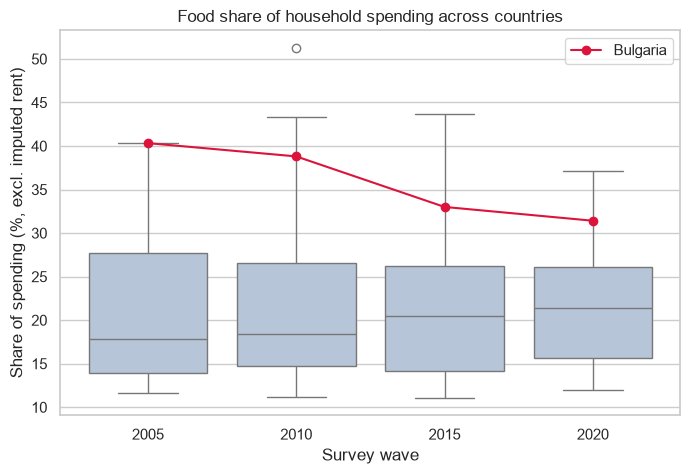

In [23]:
food = "Food and non-alcoholic beverages"
food_df = analysis[analysis["category"] == food]

years = sorted(food_df["year"].unique())
pos = {y: i for i, y in enumerate(years)}

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=food_df, x="year", y="share_excl_pct", color="lightsteelblue", ax=ax)

# Highlight Bulgaria
bg_food = food_df[food_df["country"] == "Bulgaria"].sort_values("year")
ax.plot(
    [pos[y] for y in bg_food["year"]],
    bg_food["share_excl_pct"],
    "o-",
    color="crimson",
    label="Bulgaria",
)

ax.set_title("Food share of household spending across countries")
ax.set_xlabel("Survey wave")
ax.set_ylabel("Share of spending (%, excl. imputed rent)")
ax.legend()
plt.show()

**Observations.**

- Food is the largest spending category in every survey wave, at roughly 21-22% of the budget
  on average, followed by housing (14.7% to 17.0%) and transport (about 14%).
- The housing share grows over time, while clothing (6.7% to 5.3%) and recreation
  (9.0% to 7.5%) decline and health grows slightly (3.9% to 4.6%).
- Bulgaria's food share (40.3% in 2005, 31.4% in 2020) is above the upper quartile of the
  countries in every wave, but the gap narrows: Bulgaria's share falls by about 9 percentage
  points while the median across countries rises slightly (from about 18% to about 21%).

*Caveat:* the averages are unweighted means over countries, and the set of countries differs
between waves (24, 32, 34 and 28 countries), so small changes between waves should not be
read as a clean trend.

## 6. Bulgaria vs the EU

_Comparison of the spending profile, ranking of countries, changes over time._

### 6.1 Ranking of countries by food share (2020)

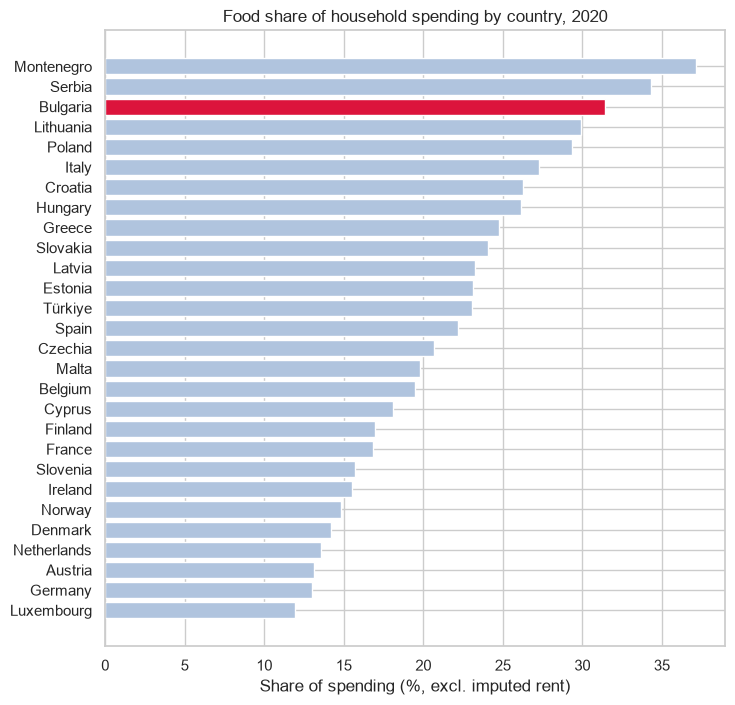

Bulgaria ranks 3 of 28 countries


In [24]:
food_2020 = (
    analysis[(analysis["year"] == 2020) & (analysis["category"] == food)]
    .sort_values("share_excl_pct")
)

# Highlight Bulgaria
colors = ["crimson" if c == "Bulgaria" else "lightsteelblue" for c in food_2020["country"]]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(food_2020["country"], food_2020["share_excl_pct"], color=colors)
ax.set_title("Food share of household spending by country, 2020")
ax.set_xlabel("Share of spending (%, excl. imputed rent)")
plt.show()

# Bulgaria's rank (1 = highest food share)
ranked = food_2020.sort_values("share_excl_pct", ascending=False).reset_index(drop=True)
rank = ranked.index[ranked["country"] == "Bulgaria"][0] + 1
print("Bulgaria ranks", rank, "of", len(ranked), "countries")

In [25]:
food_df.sort_values("share_excl_pct", ascending=False).head(5)[["country", "year", "share_excl_pct"]]

,country,year,share_excl_pct
101,Montenegro,2010,51.285347
155,Kosovo*,2015,43.705220
105,North Macedonia,2015,43.300000
104,North Macedonia,2010,43.300000
130,Romania,2010,41.015625


In [26]:
# Bulgaria: food share and GDP per capita (PPP) across the survey waves
bg_trend = (
    analysis[(analysis["country"] == "Bulgaria") & (analysis["category"] == food)]
    [["year", "share_excl_pct", "gdp_pc_ppp"]]
    .round(1)
)
bg_trend

,year,share_excl_pct,gdp_pc_ppp
13,2005,40.3,10291.4
14,2010,38.8,14954.3
15,2015,33.0,18896.1
16,2020,31.4,27351.9


**Observation.** Between 2005 and 2020 Bulgaria's GDP per capita (PPP, current international
dollars) rose from about 10,300 to about 27,400, while the food share of household spending
fell from 40.3% to 31.4%. This is consistent with Engel's law, but four points cannot confirm it;
the relationship is tested across countries in section 8. Note that the GDP series is not
adjusted for inflation, so its growth over time is overstated in real terms.

### 6.2 Spending profile: Bulgaria vs the other countries (2020)

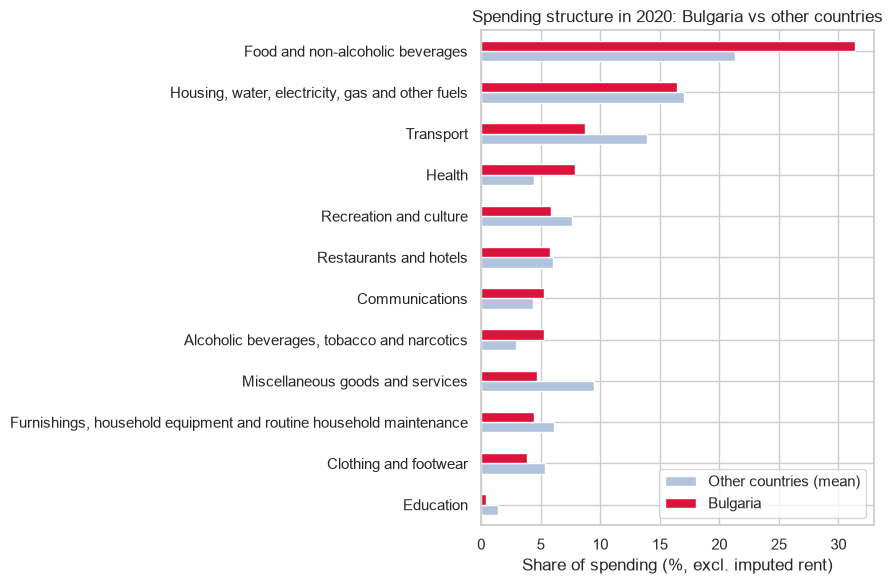

In [27]:
data_2020 = analysis[analysis["year"] == 2020].copy()
data_2020["group"] = data_2020["country"].where(
    data_2020["country"] == "Bulgaria", "Other countries (mean)"
)

profile = (
    data_2020.groupby(["category", "group"])["share_excl_pct"]
    .mean()
    .unstack("group")
    .sort_values("Bulgaria")
)

ax = profile[["Other countries (mean)", "Bulgaria"]].plot.barh(
    figsize=(9, 6), color=["lightsteelblue", "crimson"]
)
ax.set_title("Spending structure in 2020: Bulgaria vs other countries")
ax.set_xlabel("Share of spending (%, excl. imputed rent)")
ax.set_ylabel("")
ax.legend(title=None, loc="lower right")
plt.tight_layout()
plt.show()

**Observation.** Compared with the average of the other countries in 2020, Bulgarian
households spend a much larger share on food and a larger share on health and on alcohol and
tobacco. They spend a smaller share on transport, recreation and culture, clothing,
household furnishings and miscellaneous goods and services. The housing share (excluding
imputed rent) is similar. This is the typical pattern of a lower-income country, where basic
needs take a larger part of the budget.

## 7. Clustering of Countries

_K-means on the spending profile, PCA for visualisation. Which countries are closest to Bulgaria?_

### 7.1 Feature matrix and nearest countries

Each country is described by a vector of 12 spending shares (2020, excluding imputed rent).
The similarity of two countries is the Euclidean distance between their vectors:
`d(a, b) = sqrt(sum_k (a_k - b_k)^2)`, where `k` runs over the 12 categories.

In [28]:
# One row per country, one column per spending category (2020)
features = (
    analysis[analysis["year"] == 2020]
    .pivot(index="country", columns="category", values="share_excl_pct")
)
print(features.shape)   # (countries, categories)

# Euclidean distance of every country to Bulgaria
dist_to_bg = ((features - features.loc["Bulgaria"]) ** 2).sum(axis=1) ** 0.5
dist_to_bg.drop("Bulgaria").sort_values().head(5).round(1)

(28, 12)


country
Lithuania    5.5
Serbia       5.6
Poland       5.9
Hungary      8.2
Italy        8.9
dtype: float64

**Observation.** In 2020 the countries with the spending structure closest to Bulgaria are
Lithuania, Serbia and Poland (Euclidean distance of about 5.5-5.9 percentage points), followed
by Hungary and Italy. Most of them are Central and Eastern European countries with similar
income levels.

### 7.2 K-means clustering

Each category is standardised (z-score) so that every category has the same weight. The number
of clusters k is chosen with the silhouette score, which measures how well each country fits
its own cluster compared with the nearest other cluster (values from -1 to 1, higher is better).

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = StandardScaler().fit_transform(features)

# Silhouette score for k = 2..8 (fixed random_state for reproducibility)
scores = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    scores[k] = silhouette_score(X, labels)

pd.Series(scores, name="silhouette").round(3)

2    0.205
3    0.213
4    0.171
5    0.167
6    0.175
7    0.166
8    0.117
Name: silhouette, dtype: float64

**Choice of k.** The silhouette score is highest for k = 3 (0.213), but only slightly above
k = 2 (0.205), and all values are low (below 0.25). The countries therefore do not form clearly
separated groups; the clusters describe regions of a continuum rather than distinct types.
We use k = 3 as a practical compromise.

In [30]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)

clusters = features.copy()
clusters["cluster"] = km.labels_

# Members of each cluster
for c, members in clusters.groupby("cluster"):
    print(f"Cluster {c} ({len(members)} countries):", ", ".join(sorted(members.index)))

# Average share of the main categories per cluster
main_cols = [food, "Housing, water, electricity, gas and other fuels", "Transport"]
clusters.groupby("cluster")[main_cols].mean().round(1)

Cluster 0 (13 countries): Bulgaria, Croatia, Czechia, Estonia, Hungary, Italy, Latvia, Lithuania, Montenegro, Poland, Serbia, Slovakia, Türkiye
Cluster 1 (11 countries): Austria, Belgium, Denmark, Finland, France, Germany, Ireland, Luxembourg, Netherlands, Norway, Slovenia
Cluster 2 (4 countries): Cyprus, Greece, Malta, Spain


category,Food and non-alcoholic beverages,"Housing, water, electricity, gas and other fuels",Transport
cluster,,,
0,27.4,17.2,12.0
1,15.0,18.1,16.0
2,21.2,13.0,13.2


### 7.3 PCA visualisation

Principal component analysis (PCA) projects the 12-dimensional country vectors onto the two
orthogonal directions of largest variance (the principal components), so that the clusters can
be inspected in a plane.

Explained variance ratio: [0.37 0.21]


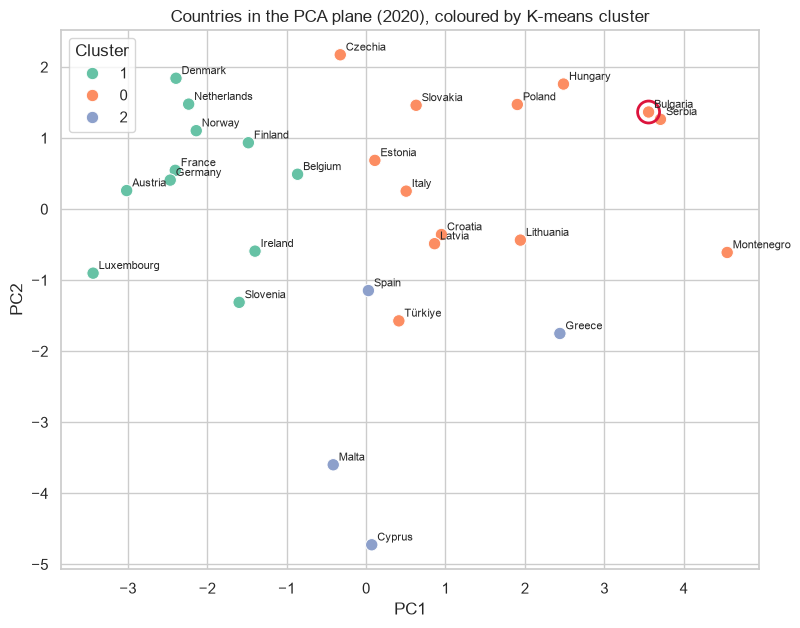

In [31]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coords = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(2))

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(
    x=coords[:, 0], y=coords[:, 1],
    hue=clusters["cluster"].astype(str), palette="Set2", s=80, ax=ax,
)
for name, (x, y) in zip(features.index, coords):
    ax.annotate(name, (x, y), fontsize=8, xytext=(4, 3), textcoords="offset points")

# Circle Bulgaria
bg_i = list(features.index).index("Bulgaria")
ax.scatter(coords[bg_i, 0], coords[bg_i, 1], s=250, facecolors="none",
           edgecolors="crimson", linewidths=2)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Countries in the PCA plane (2020), coloured by K-means cluster")
ax.legend(title="Cluster")
plt.show()

**Observation.** The first two principal components explain 37% and 21% of the variance (58% in
total). PC1 orders the countries from high-income Western and Northern Europe (left) to
lower-income countries such as Bulgaria, Serbia and Montenegro (right). Bulgaria lies in the
cluster of Central and Eastern European countries and is almost indistinguishable from Serbia.
Cluster 2 contains only Spain and Greece, which shows that the clustering is sensitive to the
choice of k (see the low silhouette scores above).

In [32]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=features.columns,
    columns=["PC1", "PC2"],
).round(2)
loadings.sort_values("PC1")

,PC1,PC2
category,,
Recreation and culture,-0.36,0.19
Miscellaneous goods and services,-0.33,0.04
Transport,-0.33,-0.21
"Furnishings, household equipment and routine household maintenance",-0.27,-0.06
Restaurants and hotels,-0.20,-0.42
"Housing, water, electricity, gas and other fuels",-0.11,0.52
Education,0.06,-0.50
Clothing and footwear,0.12,-0.39
Health,0.27,-0.16


**Interpretation of the components.** PC1 contrasts necessities (food, communications, alcohol
and tobacco, health) with discretionary spending (recreation and culture, miscellaneous
services, transport, furnishings, restaurants). Countries on the right, including Bulgaria,
therefore spend a larger part of their budget on necessities. PC2 contrasts housing with
education, restaurants and clothing. The sign of a principal component is arbitrary, so only
the relative pattern is interpreted.

## 8. Regression: Food Share vs Income per Capita

_Model, assumptions, diagnostics and interpretation._

## 9. Conclusions, Limitations and Next Steps

_Answer the research questions. Note the limitations (e.g. HBS is conducted roughly every 5 years, methodologies differ between sources)._

## 10. Sources and Licences

_Table name, URL, download date and licence for every dataset and reference._